<a href="https://colab.research.google.com/github/KudjoJedidiah/Kaggle/blob/main/DigitRecognizer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import torch
from torch import nn,optim
import torch.nn.functional as F
from torch.utils.data import Dataset,DataLoader
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
path_train='/content/drive/MyDrive/Kaggle/train.csv'
path_test='/content/drive/MyDrive/Kaggle/test.csv'

In [5]:
train_df=pd.read_csv(path_train)
test_df=pd.read_csv(path_test)

In [6]:
train_df.shape

(42000, 785)

In [7]:
test_df.shape

(28000, 784)

In [8]:
train_data,val_data=train_test_split(train_df,test_size=0.2,random_state=42)

In [9]:
class KaggleDigit(Dataset):
  def __init__(self,df,is_test=False):
    self.is_test=is_test
    if not self.is_test:
      self.labels=df.iloc[:,0].values
      self.images=((df.iloc[:,1:].values/255)-0.5)/0.5
    else:
      self.labels=None
      self.images=((df.values/255)-0.5)/0.5
    self.images=self.images.astype(np.float32)


  def __len__(self):
    return len(self.images)


  def __getitem__(self,idx):
    img=torch.tensor(self.images[idx]).view(1,28,28)
    if not self.is_test:
      label=torch.tensor(self.labels[idx],dtype=torch.long)
      return img,label
    else:
      return img


In [10]:
train_dataset=KaggleDigit(train_data)
val_dataset=KaggleDigit(val_data)
test_dataset=KaggleDigit(test_df,is_test=True)

trainloader=DataLoader(train_dataset,batch_size=64,shuffle=True)
valloader=DataLoader(val_dataset,batch_size=64,shuffle=False)
testloader=DataLoader(test_dataset,batch_size=64,shuffle=False)

In [11]:
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


In [12]:
class Classifier(nn.Module):
  def __init__(self):
    super().__init__()
    self.fc1=nn.Linear(784,256)
    self.fc2=nn.Linear(256,128)
    self.fc3=nn.Linear(128,64)
    self.fc4=nn.Linear(64,10)

  def forward(self,x):
    x=x.view(x.shape[0],-1)

    x=F.relu(self.fc1(x))
    x=F.relu(self.fc2(x))
    x=F.relu(self.fc3(x))
    x=F.log_softmax(self.fc4(x),dim=1)

    return x


In [16]:
class CNNClassifier(nn.Module):
    def __init__(self):
      super().__init__()
      self.conv1=nn.Conv2d(in_channels=1,out_channels=32,kernel_size=3,padding=1)
      self.bn1=nn.BatchNorm2d(32)

      self.conv2=nn.Conv2d(in_channels=32,out_channels=64,kernel_size=3,padding=1)
      self.bn2=nn.BatchNorm2d(64)

      self.pool=nn.MaxPool2d(kernel_size=2,stride=2)

      self.fc1=nn.Linear(64*7*7,512)
      self.bn3=nn.BatchNorm1d(512)
      self.dropout=nn.Dropout(0.5)
      self.fc2=nn.Linear(512,10)


    def forward(self,x):
      x=self.pool(F.relu(self.bn1(self.conv1(x))))
      x=self.pool(F.relu(self.bn2(self.conv2(x))))

      x=x.view(x.shape[0],-1)

      x=self.dropout(F.relu(self.bn3(self.fc1(x))))

      x=F.log_softmax(self.fc2(x),dim=1)

      return x

In [25]:
from torch.optim import optimizer
model=CNNClassifier().to(device)
criterion=nn.NLLLoss()
optimizer=optim.Adam(model.parameters(),lr=0.001)


In [27]:
epochs = 10

for e in range(epochs):
    model.train()
    running_loss = 0
    for images, labels in trainloader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        log_ps = model(images)
        loss = criterion(log_ps, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    # Validation step
    model.eval()
    val_loss = 0
    accuracy = 0
    with torch.no_grad():
        for images, labels in valloader:
            images, labels = images.to(device), labels.to(device)
            log_ps = model(images)
            val_loss += criterion(log_ps, labels).item()

            ps = torch.exp(log_ps)
            top_p, top_class = ps.topk(1, dim=1)
            equals = top_class == labels.view(*top_class.shape)
            accuracy += torch.mean(equals.type(torch.FloatTensor)).item()

    train_epoch_loss = running_loss / len(trainloader)
    val_epoch_loss = val_loss / len(valloader)
    val_epoch_acc = (accuracy / len(valloader)) * 100

    print(f"Epoch {e+1}/{epochs}.. "
          f"Train Loss: {train_epoch_loss:.4f}.. "
          f"Val Loss: {val_epoch_loss:.4f}.. "
          f"Val Accuracy: {val_epoch_acc:.2f}%")

Epoch 1/10.. Train Loss: 0.0195.. Val Loss: 0.0321.. Val Accuracy: 99.11%
Epoch 2/10.. Train Loss: 0.0179.. Val Loss: 0.0326.. Val Accuracy: 98.90%
Epoch 3/10.. Train Loss: 0.0181.. Val Loss: 0.0298.. Val Accuracy: 99.08%
Epoch 4/10.. Train Loss: 0.0144.. Val Loss: 0.0318.. Val Accuracy: 99.02%
Epoch 5/10.. Train Loss: 0.0127.. Val Loss: 0.0268.. Val Accuracy: 99.16%
Epoch 6/10.. Train Loss: 0.0103.. Val Loss: 0.0273.. Val Accuracy: 99.25%
Epoch 7/10.. Train Loss: 0.0095.. Val Loss: 0.0280.. Val Accuracy: 99.23%
Epoch 8/10.. Train Loss: 0.0095.. Val Loss: 0.0361.. Val Accuracy: 99.06%
Epoch 9/10.. Train Loss: 0.0104.. Val Loss: 0.0290.. Val Accuracy: 99.16%
Epoch 10/10.. Train Loss: 0.0077.. Val Loss: 0.0306.. Val Accuracy: 99.14%


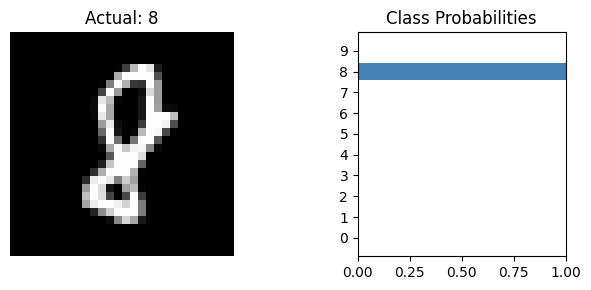

In [23]:
dataiter = iter(valloader)
images, labels = next(dataiter)
img = images[0]

model.eval()
with torch.no_grad():
    ps = torch.exp(model(img.unsqueeze(0).to(device))).cpu().squeeze().numpy()

# Display image alongside class probabilities
fig, (ax1, ax2) = plt.subplots(figsize=(7, 3), ncols=2)
ax1.imshow(img.squeeze().numpy(), cmap='gray')
ax1.axis('off')
ax1.set_title(f'Actual: {labels[0].item()}')

ax2.barh(np.arange(10), ps, color='steelblue')
ax2.set_aspect(0.1)
ax2.set_yticks(np.arange(10))
ax2.set_yticklabels(np.arange(10))
ax2.set_title('Class Probabilities')
ax2.set_xlim(0, 1.0)
plt.tight_layout()
plt.show()

In [24]:
model.eval()
test_predictions = []

with torch.no_grad():
    for images in testloader:
        images = images.to(device)
        log_ps = model(images)
        ps = torch.exp(log_ps)
        preds = torch.argmax(ps, dim=1)
        test_predictions.extend(preds.cpu().numpy())

submission = pd.DataFrame({
    'ImageId': np.arange(1, len(test_predictions) + 1),
    'Label': test_predictions
})

submission.to_csv('submission.csv', index=False)
print("Saved submission.csv successfully!")

Saved submission.csv successfully!
